# 14 - Power + gas cold snap: is the system adequate for four days of cold?

A multi-day cold snap stresses two networks at once. Heating homes burns gas, and gas-fired power
plants need the same gas. Heat pumps add electric load exactly when the outside air is coldest and
their COP is lowest. This notebook asks whether the combined system stays adequate over a 96-hour
cold snap, and which levers help: a larger battery, heat-pump demand response, or a second circuit.

The model has three parts, all in one energysim world with a 900 s macro step:

1. **Gas network** (`GasNetwork`): a national source feeds a city gate through a pipe with
   **linepack** (stored gas in the pipe). From the city gate, gas goes to the consumers in priority
   order: first **protected residential heating**, which grows as the temperature falls, then
   **power generation**.
2. **Power network** (pandapower transmission toy net): a generation bus, a load bus and an
   **interconnector** (`ext_grid`) with a notional transfer capacity (NTC). Two parallel corridor
   circuits link the import bus to the load bus.
3. **Controller** (`RuleController`): merit-order dispatch of the gas plants, plus the **gas feedback**.
   The controller tells the gas network how much fuel the *desired* dispatch needs, and it reduces
   the plant commands to the gas that was actually delivered.

Before the simulation, we look at the three ingredients that matter most: the cold-snap weather,
the gas demand that the cold creates, and the heat-pump COP that collapses at low temperature.

## Equations and assumptions

**Weather (illustrative cold snap):** `T_amb(t) = 1 - 15 (1 - exp(-t/20 h)) + 3 sin(2 pi (t - 6 h)/24 h)`, in degC.
The temperature falls from about -2 degC to about -17 degC over four days, with a daily swing of about 3 K.

**Residential gas heating (protected):** `G_res(T) = G_peak * clip((17 - T)/30, 0, 1) + G_base`, in MW (LHV).
Demand is zero above 17 degC and grows linearly as the temperature falls.

**Gas balance (per step, from `GasNetwork`):** each consumer is served in insertion order when gas is scarce.
A pipe with linepack can deliver its stored energy at its outlet node when the other sources cannot cover demand.
The pressure inside the pipe is `p = p_min + (p_max - p_min) * E_linepack / E_capacity`.

**Fuel for a dispatch:** a plant running at `P` MW with heat rate `HR` kJ/kWh (LHV) burns
`F = P * HR / 3600` MW (LHV). Example: the 1200 MW CCGT at its 6400 kJ/kWh rate burns about 2133 MW of gas.

**Power balance and adequacy:** `load = wind + CCGT + OCGT + import + battery discharge`. The interconnector
is a slack in pandapower, so the load is always met. What matters is how much of it has to come through the
NTC. We count the energy above the NTC as **expected energy not served** (EENS):

`EENS = integral of max(0, import(t) - NTC) dt`

**Gas feedback and its delay:** the controller measures what was delivered to power generation during the
last macro step, and the plants run over the next step. The gas network therefore sees the *desired* fuel demand
(`fuel_request_MW`), not the reduced one, so the gas balance does not chatter. The plants run on a derated
command `P_cmd = P_desired * delivered / (delivered + unserved)`, which follows the delivered share of the
requested gas with one macro-step delay.

**Heat pumps and COP:** `P_el = Q_heat / COP(T_amb)`. The COP lookup falls from 3.7 at +12 degC to 0.9 at -17 degC and is
floored at 1.0 in the fleet (resistive backup). Heat pumps therefore add the most electric load in the coldest hours.

**Parameters are illustrative.** Plant sizes, pipeline capacities, the NTC and the storage size are toy values
chosen so the cold snap bites. They are not a model of any real system.

## Imports and the simulation guard

This notebook needs pandapower and scipy. If either is missing, the simulation cells are skipped with a message,
and the plots of the inputs still run.

In [1]:
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from energysim import world, Ensemble
from energysim.control import RuleController
from energysim.container import BatteryFleetAdapter
from energysim.models import CombinedCycle_CCGT, GasTurbine_OCGT, WindTurbine
from energysim.models.common import Curve1D
from energysim.networks import GasNetwork

HAS_PP = importlib.util.find_spec("pandapower") is not None
HAS_SCIPY = importlib.util.find_spec("scipy") is not None
RUN = HAS_PP and HAS_SCIPY
if RUN:
    import pandapower as pp
else:
    print("pandapower and scipy are needed for the simulation cells. "
          f"Found pandapower: {HAS_PP}, scipy: {HAS_SCIPY}. The simulation cells are skipped.")

## Fleet model: heat pumps with a collapsing COP

The compact heat-pump fleet from notebook 12 is reused. Here we pass a colder COP curve, which
shows the cold-snap effect. Defrost cycles and resistive backup push the COP towards 1 below -10 degC.

In [2]:
# --- Compact heat-pump + 1R1C building fleet (shared by notebooks 12 and 14) -------------------
import numpy as np
from energysim.container import VectorizedContainerAdapter
from energysim.models.common import Curve1D

#: Illustrative COP(T_amb) for an air-source heat pump at 35 C flow (replace with test data).
HP_COP_MILD = Curve1D([-15, -7, 2, 7, 12], [2.2, 2.6, 3.2, 3.7, 4.2], name="COP_mild")


class HeatPumpFleet(VectorizedContainerAdapter):
    """N heat-pump homes: 1R1C envelope, thermostat with hysteresis, COP(T_amb) lookup.

    Per home i (explicit Euler, step h):

        C_i dT_i/dt = Q_heat_i - (T_i - T_amb) / R_i
        on_i  : switches on below  T_set - db/2, off above T_set + db/2 (hysteresis)
        Q_heat_i = on_i * Qmax_i * dr_limit                      [kW heat]
        P_el_i   = Q_heat_i / COP(T_amb)                         [kW electric]

    ``dr_limit`` (0..1) is a demand-response input that caps the compressor capacity; a
    value of 0 switches the fleet off (homes cool down through their envelope).

    Parameters are drawn per home from uniform ranges with a fixed seed, so runs are
    deterministic.  Setting ``q_heat_max_kw`` to 0 for a home removes its heat pump
    (used for the penetration sweeps).

    Inputs : t_ambient_degc [degC], dr_limit [1]
    States : t_indoor [degC], on [0/1], p_kw [kW], q_heat_kw [kW], cop [1]
    Totals : total_p_kw, total_q_heat_kw, mean_t_indoor, min_t_indoor (via the container)
    """

    units = {
        "t_ambient_degc": "degC", "dr_limit": "1",
        "t_indoor": "degC", "on": "1", "p_kw": "kW", "q_heat_kw": "kW", "cop": "1",
    }

    def __init__(self, name="hp_fleet", size=100, cop_curve=HP_COP_MILD, setpoint_degc=20.0,
                 deadband_k=1.0, q_heat_max_kw=None, rng_seed=0, t_init_degc=20.0,
                 step_size=900.0, **kwargs):
        super().__init__(name=name, size=size, step_size=step_size)
        rng = np.random.default_rng(rng_seed)
        self.c_th = rng.uniform(8.0, 16.0, self.size)                  # kWh/K
        self.r_th = rng.uniform(6.0, 10.0, self.size)                  # K/kW
        qmax = rng.uniform(4.0, 7.0, self.size) if q_heat_max_kw is None else \
            self._as_vector(q_heat_max_kw, "q_heat_max_kw")
        self.q_max = np.asarray(qmax, dtype=float)                     # kW heat
        self.cop_curve = cop_curve
        self.setpoint = float(setpoint_degc)
        self.deadband = float(deadband_k)

        t0 = rng.normal(t_init_degc, 0.5, self.size)
        self.register_state("t_indoor", t0)
        self.register_state("on", np.ones(self.size))
        self.register_state("p_kw", 0.0)
        self.register_state("q_heat_kw", 0.0)
        self.register_state("cop", 3.0)
        self.register_input("t_ambient_degc", 0.0)
        self.register_input("dr_limit", 1.0)

    def step(self, time, step_size=None):
        dt_s = float(step_size) if step_size is not None else self.step_size
        if dt_s <= 0.0:
            return
        h = dt_s / 3600.0
        t_in = self.states["t_indoor"]
        t_amb = self.input_values["t_ambient_degc"]
        dr = np.clip(self.input_values["dr_limit"], 0.0, 1.0)

        half = 0.5 * self.deadband
        on = np.where(t_in < self.setpoint - half, 1.0,
                      np.where(t_in > self.setpoint + half, 0.0, self.states["on"]))
        q_heat = on * self.q_max * dr
        cop = np.maximum(np.asarray(self.cop_curve(t_amb), dtype=float), 1.0)
        q_loss = (t_in - t_amb) / self.r_th

        self.states["t_indoor"][:] = t_in + (q_heat - q_loss) / self.c_th * h
        self.states["on"][:] = on
        self.states["q_heat_kw"][:] = q_heat
        self.states["p_kw"][:] = q_heat / cop
        self.states["cop"][:] = cop

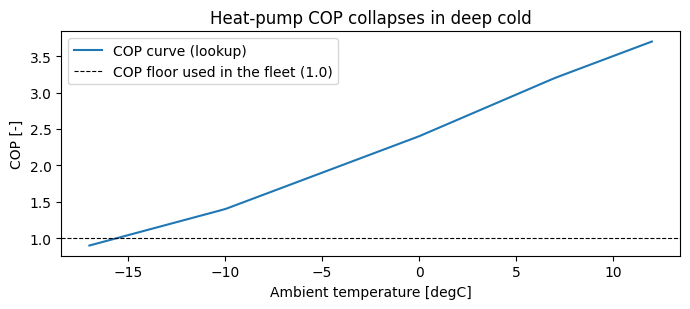

In [3]:
COP_COLD = Curve1D([-17, -10, -5, 0, 7, 12], [0.9, 1.4, 1.9, 2.4, 3.2, 3.7], name="COP_collapse")

t_grid = np.linspace(-17.0, 12.0, 120)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(t_grid, COP_COLD(t_grid), color="C0", label="COP curve (lookup)")
ax.axhline(1.0, color="k", ls="--", lw=0.8, label="COP floor used in the fleet (1.0)")
ax.set_xlabel("Ambient temperature [degC]")
ax.set_ylabel("COP [-]")
ax.set_title("Heat-pump COP collapses in deep cold")
ax.legend()
plt.tight_layout()
plt.show()

## Cold-snap drivers

The weather drives everything: heat-pump load, residential gas demand, and the wind speed that sets wind output.
The wind is calm for the whole snap (mostly below the 3 m/s cut-in speed), which is a common winter
situation during a high-pressure system. Base electric load follows the usual daily shape.

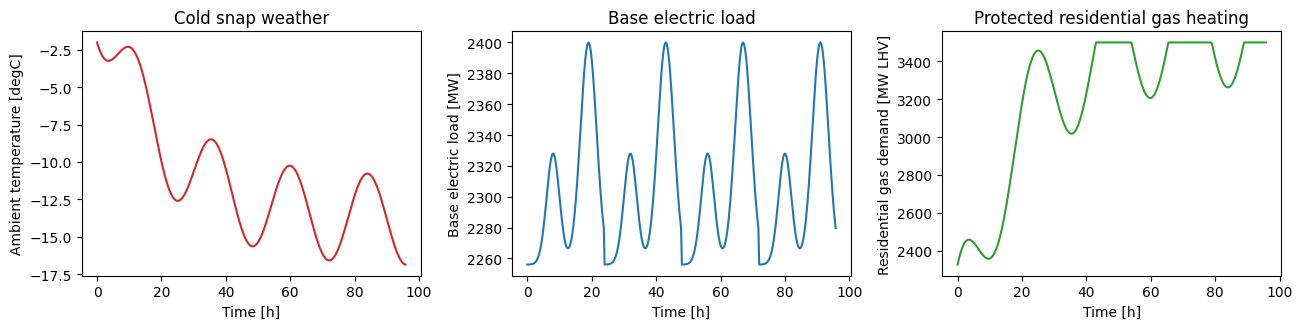

In [4]:
T_END_H = 96.0
MACRO_S = 900
HP_HOMES = 100_000
HP_QMAX_KW = 4.0
PIPE_BASE_MW = 8000.0
PIPE_RESTRICTED_MW = 5000.0
SOURCE_MW = 9000.0
LINEPACK_MWH = 3000.0
RES_GAS_PEAK_MW = 3200.0
RES_GAS_BASE_MW = 300.0
BASE_LOAD_MW = 2400.0
CCGT_MW, HR_CCGT = 1200.0, 6400.0           # kJ/kWh LHV
OCGT_MW, HR_OCGT = 600.0, 9800.0
WIND_MW = 400.0
CIRCUIT_NTC_MW = 500.0                       # notional transfer capacity per corridor circuit
BATT_N, BATT_KWH = 500, 2000.0               # 500 units x 2 MWh = 1 GWh
BATT_MAX_DIS_MW = 300.0
REPORT_STEP_H = MACRO_S / 3600.0


def t_ambient(t):
    h = float(t) / 3600.0
    return 1.0 - 15.0 * (1.0 - np.exp(-h / 20.0)) + 3.0 * np.sin(2.0 * np.pi * (h - 6.0) / 24.0)


def wind_speed(t):
    h = float(t) / 3600.0
    return max(0.0, 2.0 + 1.5 * np.sin(2.0 * np.pi * h / 48.0))


def daily_shape(t):
    h = (float(t) / 3600.0) % 24.0
    return 0.6 + 0.4 * np.exp(-0.5 * ((h - 19.0) / 2.5) ** 2) + 0.2 * np.exp(-0.5 * ((h - 8.0) / 2.0) ** 2)


def base_load_mw(t):
    return BASE_LOAD_MW * (0.85 + 0.15 * daily_shape(t))


def gas_residential_mw(t):
    return RES_GAS_BASE_MW + RES_GAS_PEAK_MW * float(np.clip((17.0 - t_ambient(t)) / 30.0, 0.0, 1.0))


t_hours = np.arange(0.0, T_END_H, REPORT_STEP_H)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(t_hours, [t_ambient(3600 * h) for h in t_hours], color="C3")
axes[0].set_ylabel("Ambient temperature [degC]")
axes[0].set_title("Cold snap weather")
axes[1].plot(t_hours, [base_load_mw(3600 * h) for h in t_hours], color="C0")
axes[1].set_ylabel("Base electric load [MW]")
axes[1].set_title("Base electric load")
axes[2].plot(t_hours, [gas_residential_mw(3600 * h) for h in t_hours], color="C2")
axes[2].set_ylabel("Residential gas demand [MW LHV]")
axes[2].set_title("Protected residential gas heating")
for ax in axes:
    ax.set_xlabel("Time [h]")
plt.tight_layout()
plt.show()

## Gas network: source, city gate with linepack, and priority consumers

The **source** is a national supply. The **pipe** `Source-CityGate` carries gas to the city gate and has
linepack. The gas then goes to two consumers, in this order: `Residential` (protected) and `PowerGen`.
A pipe with linepack can supply gas from storage when the other sources cannot meet demand.

In [5]:
def build_gas(pipe_mw):
    gas = GasNetwork(name="gas", step_size=MACRO_S, unit="MW_LHV", p_min_bar=40.0, p_max_bar=70.0)
    gas.add_producer("Source", capacity=SOURCE_MW, cost=20.0)
    gas.add_junction("CityGate")
    gas.add_consumer("Residential", demand=0.0)     # priority: first in insertion order
    gas.add_consumer("PowerGen", demand=0.0)
    gas.add_pipe("Source", "CityGate", capacity=pipe_mw, linepack_capacity_mwh=LINEPACK_MWH,
                 linepack_init=0.8, name="Source-CityGate")
    gas.add_pipe("CityGate", "Residential", capacity=20000.0, name="CityGate-Res")
    gas.add_pipe("CityGate", "PowerGen", capacity=20000.0, name="CityGate-Power")
    # The unit registry has no 'MW_LHV'. Declare the gas flows as 'MW': the numbers are the same on an LHV basis.
    gas.units = {k: ("MW" if v == "MW_LHV" else v) for k, v in gas.units.items()}
    return gas

## Power network: transmission toy net with an interconnector and two corridors

The **load** sits at the `LOAD` bus, and the three plants (CCGT, OCGT and wind) connect at the `GEN` bus
through the `Tie_GEN` line. The **interconnector** is an `ext_grid` at the `IMPORT` bus, which is connected
to the load bus through two parallel corridors (`Corridor_A` and `Corridor_B`). The N-1 scenario removes
one corridor, which lowers the notional NTC.

In [6]:
def build_power(n_circuits=2):
    net = pp.create_empty_network(name="transmission_14", f_hz=50.0, sn_mva=1000.0)
    imp = pp.create_bus(net, vn_kv=380.0, name="IMPORT")
    load = pp.create_bus(net, vn_kv=380.0, name="LOAD")
    gen = pp.create_bus(net, vn_kv=380.0, name="GEN")
    pp.create_ext_grid(net, imp, vm_pu=1.0, name="Interconnector")
    for c in range(n_circuits):
        pp.create_line(net, imp, load, length_km=60.0, std_type="490-AL1/64-ST1A 380.0",
                       name=f"Corridor_{'AB'[c]}")
    pp.create_line(net, gen, load, length_km=40.0, std_type="490-AL1/64-ST1A 380.0", name="Tie_GEN")
    pp.create_load(net, load, p_mw=BASE_LOAD_MW, q_mvar=0.0, name="Demand")   # consistent first measurement
    pp.create_sgen(net, gen, p_mw=0.0, q_mvar=0.0, name="CCGT")
    pp.create_sgen(net, gen, p_mw=0.0, q_mvar=0.0, name="OCGT")
    pp.create_sgen(net, gen, p_mw=0.0, q_mvar=0.0, name="Wind")
    return net

## Controller: merit order and the gas feedback

Each macro step the controller measures the load, the wind, the import, and the gas delivered and
unserved to power generation during the last step. It then decides:

1. **Desired dispatch.** The net load after wind is served by the CCGT first, then by the OCGT. Anything left
   is the import, which the interconnector supplies.
2. **Fuel request.** `fuel_request_MW = P_CCGT,des * HR_CCGT/3600 + P_OCGT,des * HR_OCGT/3600`, the gas that
   the *desired* dispatch needs. This value goes to the `PowerGen` consumer, so the gas balance does not depend
   on the derated commands.
3. **Derated commands.** The delivered share of the gas requested is `r = delivered / (delivered + unserved)`,
   and the plants run at `P_cmd = P_desired * r`.
4. **Optional levers.** A battery fleet discharges when the import is above 80 % of the NTC. Heat-pump
   demand response halves the compressor capacity when the import is above 90 % of the NTC.

The commands act one macro step after the measurements (`actuation_delay=True`). Everything is therefore
one 15-minute step behind the physical state, which is also how the real control loop works.

In [7]:
def make_rule(ntc_mw, battery, hp_dr):
    def rule(t, m, f):
        need = max(0.0, m["load_MW"] - m["wind_MW"])
        ccgt_des = min(need, CCGT_MW)
        ocgt_des = min(max(0.0, need - ccgt_des), OCGT_MW)
        fuel_req = ccgt_des * HR_CCGT / 3600.0 + ocgt_des * HR_OCGT / 3600.0
        supplied = m["gas_delivered_MW"] + m["gas_unserved_MW"]
        ratio = m["gas_delivered_MW"] / supplied if supplied > 1e-6 else 1.0
        ratio = min(1.0, max(0.0, ratio))
        out = {"ccgt_cmd_MW": ccgt_des * ratio, "ocgt_cmd_MW": ocgt_des * ratio,
               "fuel_request_MW": fuel_req}
        if battery:
            discharge = min(BATT_MAX_DIS_MW, max(0.0, m["import_MW"] - 0.8 * ntc_mw))
            out["batt_cmd_kw"] = -discharge * 1000.0 / BATT_N          # per unit, kW (+ charge)
        if hp_dr:
            out["dr_limit"] = 0.5 if m["import_MW"] > 0.9 * ntc_mw else 1.0
        return out
    return rule

## Assembling the world

`make_world` takes the scenario levers as parameters: the number of corridor circuits, the pipeline
capacity, the battery fleet and the heat-pump demand response. The signal `ntc` is recorded as a
time series, so the EENS KPI reads the NTC of each run from its own results.

In [8]:
def make_world(n_circuits=2, pipe_mw=PIPE_BASE_MW, battery=False, hp_dr=False, t_end_h=T_END_H):
    ntc = n_circuits * CIRCUIT_NTC_MW
    sim = world(start_time=0, stop_time=t_end_h * 3600.0, t_macro=MACRO_S, power_unit="MW")

    sim.add_signal("t_amb", lambda t: float(t_ambient(t)), step_size=MACRO_S, units={"y": "degC"})
    sim.add_signal("wind_speed", lambda t: float(wind_speed(t)), step_size=MACRO_S, units={"y": "m/s"})
    sim.add_signal("base", lambda t: float(base_load_mw(t)), step_size=MACRO_S, units={"y": "MW"})
    sim.add_signal("gas_res", lambda t: float(gas_residential_mw(t)), step_size=MACRO_S,
                   units={"y": "MW"})
    sim.add_signal("ntc", float(ntc), step_size=MACRO_S, units={"y": "MW"})

    sim.add_model("gas", model=build_gas(pipe_mw), step_size=MACRO_S)
    corridor_cols = [f"Corridor_{'AB'[c]}.loading_percent" for c in range(n_circuits)]
    sim.add_powerflow(
        network_name="grid", model=build_power(n_circuits),
        inputs=["Demand.p_mw", "CCGT.p_mw", "OCGT.p_mw", "Wind.p_mw"],
        outputs=["Interconnector.p_mw", "Demand.p_mw", "CCGT.p_mw", "OCGT.p_mw", "Wind.p_mw",
                 "Tie_GEN.loading_percent"] + corridor_cols,
        step_size=MACRO_S, mode="ac",
    )
    sim.add_model("ccgt", model=CombinedCycle_CCGT(name="ccgt", p_rated_mw=CCGT_MW, step_size=MACRO_S),
                  inputs=["P_cmd", "T_amb"], outputs=["P_actual", "fuel_consumption_MMBtu_hr"],
                  step_size=MACRO_S)
    sim.add_model("ocgt", model=GasTurbine_OCGT(name="ocgt", p_rated_mw=OCGT_MW, step_size=MACRO_S),
                  inputs=["P_cmd", "T_amb"], outputs=["P_actual", "state"], step_size=MACRO_S)
    sim.add_model("wind", model=WindTurbine(name="wind", p_rated_mw=WIND_MW, step_size=MACRO_S),
                  inputs=["v_wind", "T_amb"], outputs=["P_actual"], step_size=MACRO_S)
    sim.add_fleet(sim_name="hp", container=HeatPumpFleet(name="hp", size=HP_HOMES, cop_curve=COP_COLD,
                                                        q_heat_max_kw=HP_QMAX_KW, rng_seed=14,
                                                        step_size=MACRO_S),
                  outputs=["total_p_kw", "mean_t_indoor", "min_t_indoor"])
    if battery:
        sim.add_fleet(sim_name="batt",
                      container=BatteryFleetAdapter(name="batt", size=BATT_N, capacity_kwh=BATT_KWH,
                                                    max_charge_kw=300.0, max_discharge_kw=600.0,
                                                    initial_soc=0.8, soc_min=0.1, soc_max=0.95,
                                                    efficiency=0.88, step_size=MACRO_S),
                      outputs=["total_actual_p_kw", "mean_soc"])

    measurements = ["load_MW", "wind_MW", "import_MW", "gas_delivered_MW", "gas_unserved_MW"]
    setpoints = ["ccgt_cmd_MW", "ocgt_cmd_MW", "fuel_request_MW", "batt_cmd_kw", "dr_limit"]
    ctrl = RuleController(
        make_rule(ntc, battery, hp_dr),
        measurement_inputs=measurements, setpoint_outputs=setpoints,
        units={"load_MW": "MW", "wind_MW": "MW", "import_MW": "MW", "gas_delivered_MW": "MW",
               "gas_unserved_MW": "MW", "ccgt_cmd_MW": "MW", "ocgt_cmd_MW": "MW",
               "fuel_request_MW": "MW", "batt_cmd_kw": "kW", "dr_limit": "1"},
        initial_setpoints={"dr_limit": 1.0}, step_size=MACRO_S,
        # given initial measurements, the controller decides at init(), so the plants start at t = 0
        initial_measurements={"load_MW": BASE_LOAD_MW, "wind_MW": 0.0, "import_MW": 0.0,
                              "gas_delivered_MW": 0.0, "gas_unserved_MW": 0.0},
    )
    sim.add_model("ctrl", model=ctrl, step_size=MACRO_S)

    # Demand fan-in: base load (MW) + heat-pump electric (kW) + battery charge (kW) if present.
    demand_sources = ("base.y", "hp.total_p_kw") + (("batt.total_actual_p_kw",) if battery else ())
    connections = {
        "t_amb.y": ["ccgt.T_amb", "ocgt.T_amb", "wind.T_amb", "hp.t_ambient_degc"],
        "wind_speed.y": "wind.v_wind",
        "gas_res.y": "gas.Residential.demand_MW",
        demand_sources: "grid.Demand.p_mw",
        "grid.Demand.p_mw": "ctrl.load_MW",
        "wind.P_actual": ["grid.Wind.p_mw", "ctrl.wind_MW"],
        "ccgt.P_actual": "grid.CCGT.p_mw",
        "ocgt.P_actual": "grid.OCGT.p_mw",
        "grid.Interconnector.p_mw": "ctrl.import_MW",
        "gas.PowerGen.delivered_MW": "ctrl.gas_delivered_MW",
        "gas.PowerGen.unserved_MW": "ctrl.gas_unserved_MW",
        "ctrl.ccgt_cmd_MW": "ccgt.P_cmd",
        "ctrl.ocgt_cmd_MW": "ocgt.P_cmd",
        "ctrl.fuel_request_MW": "gas.PowerGen.demand_MW",
    }
    if battery:
        connections["ctrl.batt_cmd_kw"] = "batt.p_cmd_kw"
    if hp_dr:
        connections["ctrl.dr_limit"] = "hp.dr_limit"
    sim.add_connections(connections)
    return sim

## One run: the base case, with the story in four plots

We run the base case once and plot it, before the scenario comparison. The four panels show:
(a) the gas demand against what was delivered, (b) the linepack pressure at the city gate, (c) the power balance
against the NTC and (d) the derated plant commands against the desired dispatch. Panel (d) also shows the one-step
delay of the gas feedback.

C:\Users\digvi\AppData\Local\Temp\ipykernel_13812\1283898922.py:77: UserWarning: Algebraic loop detected involving simulators: ['ccgt', 'ctrl', 'gas', 'grid', 'ocgt']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay error.
  sim.add_connections(connections)


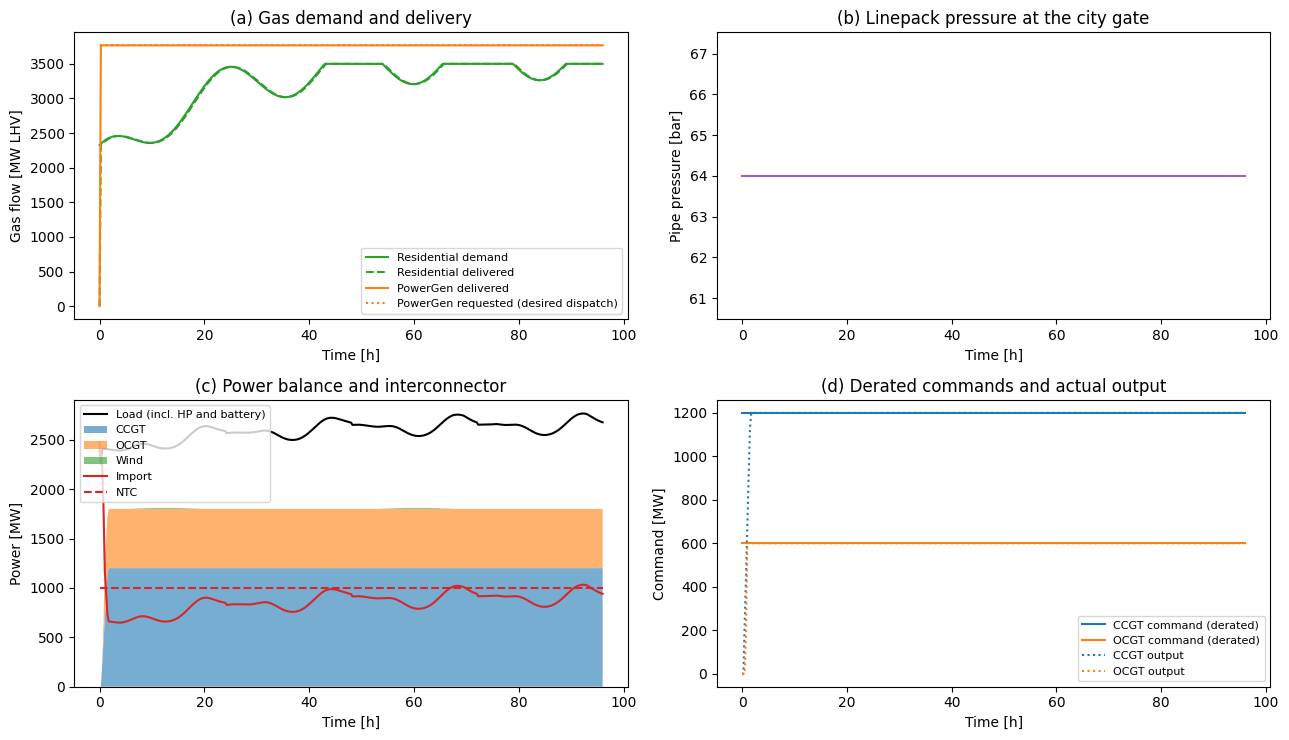

In [9]:
if RUN:
    res = make_world().simulate(pbar=False)
    h = res["ctrl.fuel_request_MW"].index / 3600.0

    fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
    ax = axes[0, 0]
    ax.plot(h, res["gas_res.y"], label="Residential demand", color="C2")
    ax.plot(h, res["gas.Residential.delivered_MW"], "--", color="C2", label="Residential delivered")
    ax.plot(h, res["gas.PowerGen.delivered_MW"], label="PowerGen delivered", color="C1")
    ax.plot(h, res["ctrl.fuel_request_MW"], ":", color="C1", label="PowerGen requested (desired dispatch)")
    ax.set_xlabel("Time [h]")
    ax.set_ylabel("Gas flow [MW LHV]")
    ax.set_title("(a) Gas demand and delivery")
    ax.legend(fontsize=8)

    ax = axes[0, 1]
    ax.plot(h, res["gas.Source-CityGate.pressure_bar"], color="C4")
    ax.set_xlabel("Time [h]")
    ax.set_ylabel("Pipe pressure [bar]")
    ax.set_title("(b) Linepack pressure at the city gate")

    ax = axes[1, 0]
    ax.plot(h, res["grid.Demand.p_mw"], color="k", label="Load (incl. HP and battery)")
    ax.stackplot(h, res["grid.CCGT.p_mw"], res["grid.OCGT.p_mw"], res["grid.Wind.p_mw"],
                 labels=["CCGT", "OCGT", "Wind"], colors=["C0", "C1", "C2"], alpha=0.6)
    ax.plot(h, res["grid.Interconnector.p_mw"], color="C3", label="Import")
    ax.plot(h, res["ntc.y"], "--", color="C3", label="NTC")
    ax.set_xlabel("Time [h]")
    ax.set_ylabel("Power [MW]")
    ax.set_title("(c) Power balance and interconnector")
    ax.legend(fontsize=8, loc="upper left")

    ax = axes[1, 1]
    ax.plot(h, res["ctrl.ccgt_cmd_MW"], color="C0", label="CCGT command (derated)")
    ax.plot(h, res["ctrl.ocgt_cmd_MW"], color="C1", label="OCGT command (derated)")
    ax.plot(h, res["grid.CCGT.p_mw"], ":", color="C0", label="CCGT output")
    ax.plot(h, res["grid.OCGT.p_mw"], ":", color="C1", label="OCGT output")
    ax.set_xlabel("Time [h]")
    ax.set_ylabel("Command [MW]")
    ax.set_title("(d) Derated commands and actual output")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("Skipped: pandapower and scipy are required.")

## Scenarios: which lever buys the most adequacy?

The Ensemble runs six scenarios on the same weather:

| # | Scenario | Change against the base case |
|---|---|---|
| 1 | base | two corridor circuits (NTC 1000 MW), pipe 8000 MW |
| 2 | N-1 corridor | one corridor circuit (NTC 500 MW) |
| 3 | pipe restricted | pipe 5000 MW |
| 4 | + battery | 1 GWh battery fleet (300 MW), discharging above 80 % of the NTC |
| 5 | + HP demand response | heat-pump compressors halved above 90 % of the NTC |
| 6 | + battery + HP DR | both levers together |

The KPIs are: unserved gas (all consumers), gas shortfall to power generation, EENS (import above the NTC), peak
corridor loading and minimum linepack pressure. Results are kept as a KPI table only (`keep="kpis"`).

In [10]:
SCENARIO_NAMES = ["base", "N-1 corridor", "pipe restricted", "+ battery",
                  "+ HP demand response", "+ battery + HP DR"]
SCENARIOS = [
    dict(n_circuits=2, pipe_mw=PIPE_BASE_MW, battery=False, hp_dr=False),
    dict(n_circuits=1, pipe_mw=PIPE_BASE_MW, battery=False, hp_dr=False),
    dict(n_circuits=2, pipe_mw=PIPE_RESTRICTED_MW, battery=False, hp_dr=False),
    dict(n_circuits=2, pipe_mw=PIPE_BASE_MW, battery=True, hp_dr=False),
    dict(n_circuits=2, pipe_mw=PIPE_BASE_MW, battery=False, hp_dr=True),
    dict(n_circuits=2, pipe_mw=PIPE_BASE_MW, battery=True, hp_dr=True),
]

_trapz = getattr(np, "trapezoid", None) or np.trapz     # numpy >= 2 renamed trapz


def energy_mwh(series):
    """Time integral of a power series [MW] in seconds -> energy [MWh]."""
    return float(_trapz(series.values, series.index.values) / 3600.0)


def kpi_unserved_gas(r):
    return energy_mwh(r["gas.Residential.unserved_MW"]) + energy_mwh(r["gas.PowerGen.unserved_MW"])


def kpi_gas_short_power(r):
    return energy_mwh(r["gas.PowerGen.unserved_MW"])


def kpi_eens(r):
    excess = (r["grid.Interconnector.p_mw"] - r["ntc.y"]).clip(lower=0.0)
    return energy_mwh(excess)


def kpi_peak_import(r):
    return float(r["grid.Interconnector.p_mw"].max())


def kpi_max_corridor_loading(r):
    cols = [c for c in ("grid.Corridor_A.loading_percent", "grid.Corridor_B.loading_percent") if c in r]
    return max(float(r[c].max()) for c in cols)


def kpi_min_pressure(r):
    return float(r["gas.Source-CityGate.pressure_bar"].min())


KPIS = {"unserved_gas_MWh": kpi_unserved_gas, "gas_short_power_MWh": kpi_gas_short_power,
        "EENS_MWh": kpi_eens, "peak_import_MW": kpi_peak_import,
        "max_corridor_loading_pct": kpi_max_corridor_loading, "min_pressure_bar": kpi_min_pressure}

In [11]:
if RUN:
    study = Ensemble(
        world_factory=lambda params, seed: make_world(**params),
        scenarios=SCENARIOS,
        kpis=KPIS,
        keep="kpis",
    ).run()

    table = study.kpis().copy()
    table.insert(0, "scenario", SCENARIO_NAMES)
    display(table.round(1))
else:
    print("Skipped: pandapower and scipy are required.")

C:\Users\digvi\AppData\Local\Temp\ipykernel_13812\1283898922.py:77: UserWarning: Algebraic loop detected involving simulators: ['ccgt', 'ctrl', 'gas', 'grid', 'ocgt']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay error.
  sim.add_connections(connections)
C:\Users\digvi\AppData\Local\Temp\ipykernel_13812\1283898922.py:77: UserWarning: Algebraic loop detected involving simulators: ['ccgt', 'ctrl', 'gas', 'grid', 'ocgt']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay error.
  sim.add_connections(connections)
C:\Users\digvi\AppData\Local\Temp\ipykernel_13812\1283898922.py:77: UserWarning: Algebraic loop detected involving simulators: ['ccgt', 'ctrl', 'gas', 'grid', 'ocgt']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay erro

,scenario,unserved_gas_MWh,gas_short_power_MWh,EENS_MWh,peak_import_MW,max_corridor_loading_pct,min_pressure_bar
run,,,,,,,
0,base,0.0,0.0,1186.6,2476.1,197.2,64.0
1,N-1 corridor,0.0,0.0,36843.2,2575.5,423.4,64.0
2,pipe restricted,186217.7,186217.7,90553.1,2612.1,208.2,40.0
3,+ battery,0.0,0.0,1064.4,2476.1,197.2,64.0
4,+ HP demand response,0.0,0.0,1138.7,2476.1,197.2,64.0
5,+ battery + HP DR,0.0,0.0,1035.8,2476.1,197.2,64.0


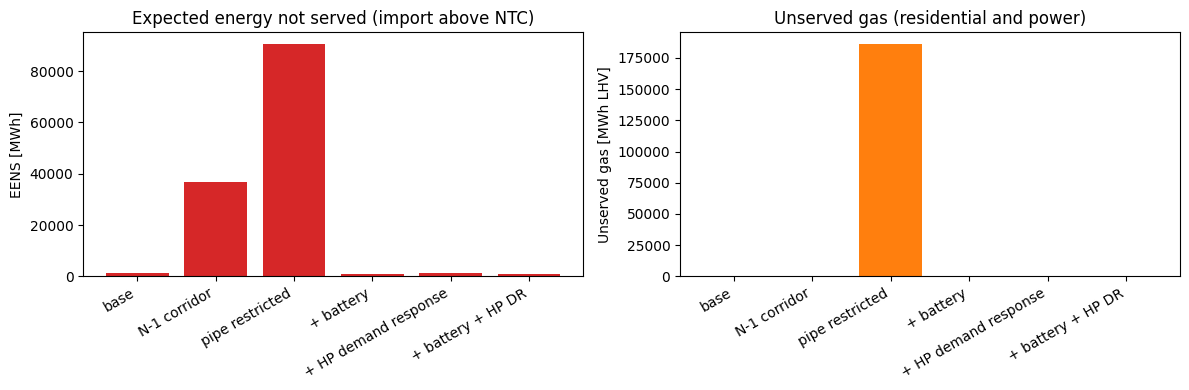

In [12]:
if RUN:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    x = np.arange(len(SCENARIO_NAMES))
    ax1.bar(x, table["EENS_MWh"], color="C3")
    ax1.set_xticks(x, SCENARIO_NAMES, rotation=30, ha="right")
    ax1.set_ylabel("EENS [MWh]")
    ax1.set_title("Expected energy not served (import above NTC)")
    ax2.bar(x, table["unserved_gas_MWh"], color="C1")
    ax2.set_xticks(x, SCENARIO_NAMES, rotation=30, ha="right")
    ax2.set_ylabel("Unserved gas [MWh LHV]")
    ax2.set_title("Unserved gas (residential and power)")
    plt.tight_layout()
    plt.show()
else:
    print("Skipped: pandapower and scipy are required.")

Energysim prints an *algebraic loop* warning for the gas feedback (plants, controller, gas and grid). This is
expected: the loop is solved with the one-step (Jacobi) delay described above.

## How to read the results

* **Residential gas is protected.** Because it is served first, the power sector absorbs the gas
  shortfall in the pipe-restricted case. The shortfall appears as a derated plant command, not as residential
  supply loss, until the linepack is empty.
* **The N-1 corridor case** lowers the NTC, so the same import now needs more of the energy above the
  interconnector limit, which the EENS KPI counts.
* **The battery buys hours, not days.** A 1 GWh store at 300 MW can cover a few hours of import above the NTC.
  Once it is empty it adds nothing, so its benefit is concentrated in the first peaks of the cold snap.
* **Heat-pump demand response** shifts heat-pump energy in time. The homes cool, and the heat deficit is recovered
  later, so the peak eases but the energy is not removed. The 1R1C model shows this in the indoor temperatures.

Caveats: toy plant and network sizes, no unit commitment or start-up limits beyond the plant models, no
gas-quality or hydraulic detail (linepack is a buffer, not a hydraulic model), unity power factor in the transmission
network, and a one-macro-step (15-minute) feedback delay. The ranking of the levers is more robust than the absolute
values.

## Where to go next

* **Notebook 12** shows the distribution-level view of heat pumps and PV, with volt-watt control and hosting
  capacity.
* **Notebook 07** is the hydrogen valley, which shows the gas-side coupling through electrolysers and hydrogen storage.
* To make the gas side hydraulic, replace the `GasNetwork` pipes with a physical model, and keep the same
  controller interface so the feedback loop stays the same.